In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.cluster import k_means
from sklearn.linear_model import LinearRegression,LogisticRegression,ElasticNet,Lasso,ridge_regression
from sklearn.tree import plot_tree,DecisionTreeRegressor
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler,OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostRegressor,BaggingClassifier,GradientBoostingClassifier,RandomForestClassifier
from sklearn.metrics import accuracy_score,auc,classification_report,silhouette_score,confusion_matrix,euclidean_distances,explained_variance_score,root_mean_squared_error,r2_score,mean_squared_error
from sklearn.model_selection import train_test_split,KFold,cross_val_score,GridSearchCV

In [5]:
house=pd.read_csv('MELBOURNE_HOUSE_PRICES_LESS.csv')
house.head(3)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,49 Lithgow St,3,h,1490000.0,S,Jellis,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,59A Turner St,3,h,1220000.0,S,Marshall,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
2,Abbotsford,119B Yarra St,3,h,1420000.0,S,Nelson,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council


In [ ]:
# Data preprocessing

In [3]:
house.shape

(63023, 13)

In [4]:
house.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63023 entries, 0 to 63022
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         63023 non-null  object 
 1   Address        63023 non-null  object 
 2   Rooms          63023 non-null  int64  
 3   Type           63023 non-null  object 
 4   Price          48433 non-null  float64
 5   Method         63023 non-null  object 
 6   SellerG        63023 non-null  object 
 7   Date           63023 non-null  object 
 8   Postcode       63023 non-null  int64  
 9   Regionname     63023 non-null  object 
 10  Propertycount  63023 non-null  int64  
 11  Distance       63023 non-null  float64
 12  CouncilArea    63023 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 6.3+ MB


In [5]:
house.isna().sum()

Suburb               0
Address              0
Rooms                0
Type                 0
Price            14590
Method               0
SellerG              0
Date                 0
Postcode             0
Regionname           0
Propertycount        0
Distance             0
CouncilArea          0
dtype: int64

<Axes: xlabel='Price', ylabel='Density'>

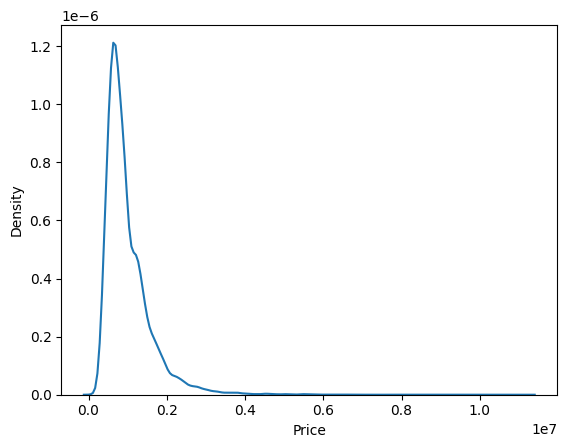

In [6]:
sns.kdeplot(house['Price'])

In [6]:
house['Price'].median()

830000.0

In [8]:
house['Price'].min()

85000.0

In [9]:
house['Price'].max()

11200000.0

In [ ]:
For filling null values in price. We can fill by median of the price is 830000.0.

In [7]:
house['Price']=house['Price'].fillna(house['Price'].median())

In [8]:
house.isna().sum()

Suburb           0
Address          0
Rooms            0
Type             0
Price            0
Method           0
SellerG          0
Date             0
Postcode         0
Regionname       0
Propertycount    0
Distance         0
CouncilArea      0
dtype: int64

In [9]:
house['Date']=pd.to_datetime(house['Date'],errors='coerce', format='mixed')

In [18]:
house['Date'].dtype

dtype('<M8[ns]')

In [10]:
house['Date']

0       2017-01-04
1       2017-01-04
2       2017-01-04
3       2017-01-04
4       2017-01-04
           ...    
63018   2018-03-31
63019   2018-03-31
63020   2018-03-31
63021   2018-03-31
63022   2018-03-31
Name: Date, Length: 63023, dtype: datetime64[ns]

In [5]:
from statsmodels.stats.weightstats import ztest
from scipy.stats import ttest_1samp,ttest_ind,ttest_rel
from scipy.stats import f_oneway
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

In [8]:
house.head(3)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,49 Lithgow St,3,h,1490000.0,S,Jellis,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,59A Turner St,3,h,1220000.0,S,Marshall,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
2,Abbotsford,119B Yarra St,3,h,1420000.0,S,Nelson,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council


In [11]:
house.Regionname.unique()

array(['Northern Metropolitan', 'Western Metropolitan',
       'Southern Metropolitan', 'South-Eastern Metropolitan',
       'Eastern Metropolitan', 'Northern Victoria', 'Western Victoria',
       'Eastern Victoria'], dtype=object)

In [ ]:
# z test hypothesis statement
H0:mu=Northern Metropolitan  # sales is better
H1:mu≠Northern Metropolitan  #southern metropolitan is more selling

In [12]:
n=100
z_sample=house.head(100)


In [13]:
z_sample.groupby('Regionname')['Price'].sum()

Regionname
Eastern Metropolitan          11360000.0
Northern Metropolitan         12385000.0
South-Eastern Metropolitan     3412000.0
Southern Metropolitan         57672800.0
Western Metropolitan          10220600.0
Name: Price, dtype: float64

In [ ]:
z_test=x^-mu/sigma/root(n)

In [14]:
z_sample.groupby('Regionname')['Price'].mean()

Regionname
Eastern Metropolitan          1.032727e+06
Northern Metropolitan         1.238500e+06
South-Eastern Metropolitan    1.137333e+06
Southern Metropolitan         1.517705e+06
Western Metropolitan          7.300429e+05
Name: Price, dtype: float64

In [15]:
z_sample.groupby('Regionname')['Price'].std()

Regionname
Eastern Metropolitan          401829.339623
Northern Metropolitan         453791.496419
South-Eastern Metropolitan    254382.258291
Southern Metropolitan         673447.053216
Western Metropolitan          289065.714419
Name: Price, dtype: float64

In [16]:
mu=1.23850
x=1.51770
sigma=453791.496
n=100

In [18]:
z_test_Static=(x-mu)/(sigma/np.sqrt(n))

In [28]:
z_test_Static

6.152605380687877e-06

In [20]:
table_value=1.96

In [ ]:
two tail on 0.05% is 1.96
z<table value

In [29]:
test_static=6.15

In [30]:
if test_static<table_value:
    print('H0 is accepted')
else:
    print('H0 is rejected ')

H0 is rejected 


In [39]:
z_sample.dropna(inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_15280\2060739903.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  z_sample.dropna(inplace=True)


In [40]:
sample_mean=z_sample[z_sample['Regionname']=='Southern Metropolitan']['Price']
population_mean=z_sample[z_sample['Regionname']=='Northern Metropolitan']['Price']

In [41]:
sample_mean

9     1925000.0
17     836000.0
18    2110000.0
19    1386000.0
20     580000.0
21     355000.0
23    1270000.0
25    1610000.0
26    1435000.0
31     660800.0
32     700000.0
33    2700000.0
34    2035000.0
35     955000.0
36    1810000.0
37    1850000.0
39    2600000.0
40    1220000.0
41    2470000.0
43     800000.0
45    1285000.0
46     835000.0
47    1445000.0
49    1435000.0
51    1300000.0
52    1500000.0
53    1340000.0
55    1400000.0
57     775000.0
58     920000.0
59    1220000.0
60    1130000.0
61    1460000.0
63    3000000.0
82    2250000.0
87    1958000.0
88    2137000.0
90    2975000.0
Name: Price, dtype: float64

In [52]:
z_test,pvalue=ztest(sample_mean,value=population_mean.mean(),alternative='larger')

In [50]:
z_test

2.555712176175497

In [54]:
if z_test>1.96:
    print('H0 is reject')
else:
    print('H0 is accepted ')

H0 is reject


In [74]:
Southern=z_sample[z_sample['Regionname']=='Southern Metropolitan']
Northern=z_sample[z_sample['Regionname']=='Northern Metropolitan']

In [75]:
Southern,Northern

(            Suburb             Address  Rooms Type      Price Method  \
 9      Albert Park         18 Mills St      3    h  1925000.0      S   
 17        Armadale    2/23 Ashleigh Rd      2    u   836000.0      S   
 18        Armadale        6A Auburn Gr      2    h  2110000.0      S   
 19        Armadale         746 High St      3    h  1386000.0      S   
 20        Armadale    14/25 Kooyong Rd      2    u   580000.0     VB   
 21        Armadale  6/38 Wattletree Rd      1    u   355000.0      S   
 23       Ashburton      1/48 Karnak Rd      3    u  1270000.0      S   
 25       Ashburton     61A Victory Bvd      3    t  1610000.0      S   
 26         Ashwood       43 Douglas St      4    h  1435000.0      S   
 31          Balwyn  104/29 Belgrove Av      2    u   660800.0     SP   
 32          Balwyn    2/362 Belmore Rd      2    t   700000.0     PI   
 33          Balwyn     9 Kenilworth St      5    h  2700000.0     PI   
 34          Balwyn          4 Lynch Ct      3    h

In [66]:
# expensive column based on price
z_sample['expensive']=(z_sample['Price']>830000).astype(int)

C:\Users\Admin\AppData\Local\Temp\ipykernel_15280\1237608826.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  z_sample['expensive']=(z_sample['Price']>830000).astype(int)


In [67]:
z_sample['expensive'].unique()

array([1, 0])

In [68]:
z_sample['Price'].min(),z_sample['Price'].max(),z_sample['Price'].median()

(355000.0, 3000000.0, 1210000.0)

In [86]:
Southern['expensive'].sum()

32

In [76]:
sucess=[Southern['expensive'].sum(),Northern['expensive'].sum()]
samples=[len(Southern),len(Northern)]

In [77]:
sucess

[32, 8]

In [80]:
z_stat, p_val=ztest(sucess,samples)

In [82]:
z_stat

-0.21693045781865616

In [83]:
if abs(z_stat)<table_value:
    print('Ho is accepted')
else:
    print('rejected')

Ho is accepted


In [78]:
samples

[38, 10]

In [ ]:
one way

In [87]:
z_sample['Regionname'].unique()

array(['Northern Metropolitan', 'Western Metropolitan',
       'Southern Metropolitan', 'South-Eastern Metropolitan',
       'Eastern Metropolitan'], dtype=object)

In [88]:
region=['Northern Metropolitan', 'Western Metropolitan',
       'Southern Metropolitan',]

In [90]:
grouped_prices=[z_sample[z_sample['Regionname']==i]['Price'] for i in region]

In [92]:
# grouped_prices
H0:mu1=mu2=mu3=..
H1:mu1!=mu2 # there is one mean different

In [94]:
ftest,pvalue=f_oneway(*grouped_prices)

In [106]:
ftest

9.551628634154287

In [95]:
n=100
c=3


In [100]:
df2=n-c
df1=c-1

In [97]:
from scipy.stats import f

In [98]:
alpha=0.05

In [102]:
table=f.ppf(1-alpha,df1,df2)

In [105]:
if ftest<table:
    print('fail to accept h0 there is no differen in mean')
else:
    print(' reject h0 there is differen in mean')

failed to reject h0 there is differen in mean


In [ ]:
H0:mu_south=mu_north
H1:mu_south!=mu_north

In [108]:
first_20=house.head(20)
first_20.dropna(inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_15280\1831426607.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  first_20.dropna(inplace=True)


In [111]:
south=first_20[first_20['Regionname']=='Southern Metropolitan']['Price']
north=first_20[first_20['Regionname']=='Northern Metropolitan']['Price']

popu_mean=south.mean()

In [113]:
ttest,pval=ttest_1samp(north,popu_mean)

In [114]:
ttest

-0.012402243545338794

In [115]:
ttest_ind(south,north)

TtestResult(statistic=0.005613205277569676, pvalue=0.9956779538516422, df=7.0)

In [ ]:
chisquare for 2 categoricals
H₀ (null): Region and Property Type are independent

H₁ (alt): Region and Property Type are dependent (related)

In [117]:
contigen=pd.crosstab(z_sample['Regionname'],z_sample['Type'])

In [119]:
chi2, p, dof, expected=chi2_contingency(contigen)

In [120]:
table=15.507
if chi2<table:
    print('Fail to reject h0. both are independent')
else:
    print('reject h0, there is relationship')

Fail to reject h0. both are independent


In [2]:
!pip install statsmodels

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 2.4 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/9.9 MB 2.7 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.9 MB 2.9 MB/s eta 0:00:03
   --------- ------------------------------ 2.4/9.9 MB 2.9 MB/s eta 0:00:03
   ------------ --------------------------- 3.1/9.9 MB 3.0 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/9.9 MB 3.0 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.9 MB 3.1 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.9 MB 3.1 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.9 MB 3.1 MB/s eta 0:00:02
   -------------------------- ------------- 6.6/9.9 MB 3.2 MB/s eta 0:00:02
   ---------------------------- ----------- 7.1/9.9 MB 3.1 MB/s eta 0:00:01
   ------------------------------- -------- 7.9/9.9 MB 3.2 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 24.3.1 -> 25.1.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [121]:
numeri=house.select_dtypes(np.number)

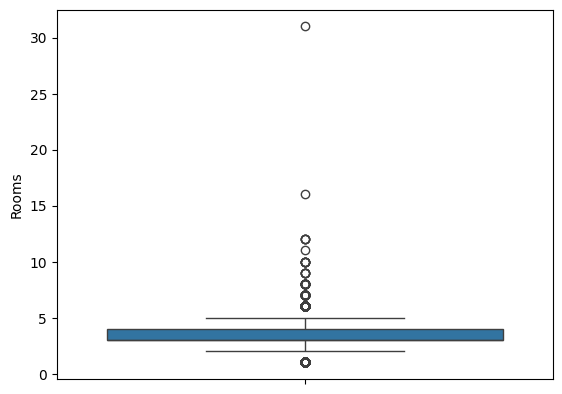

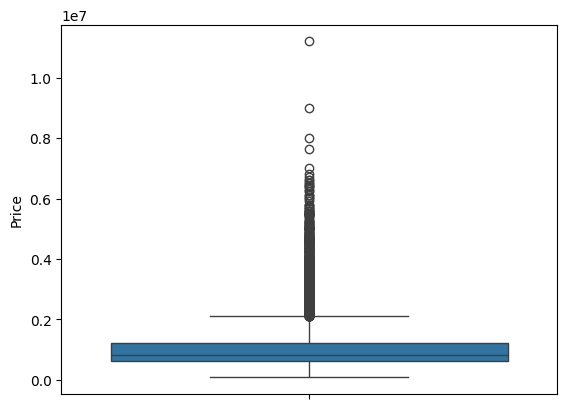

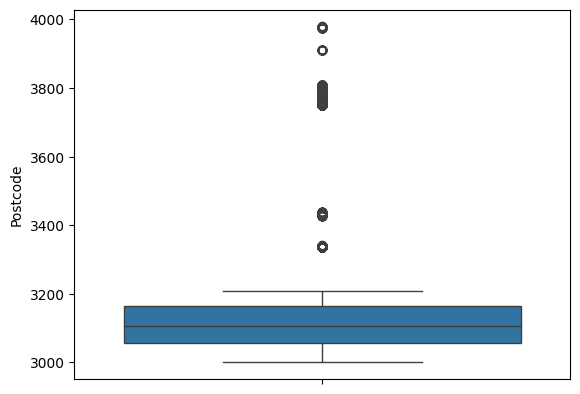

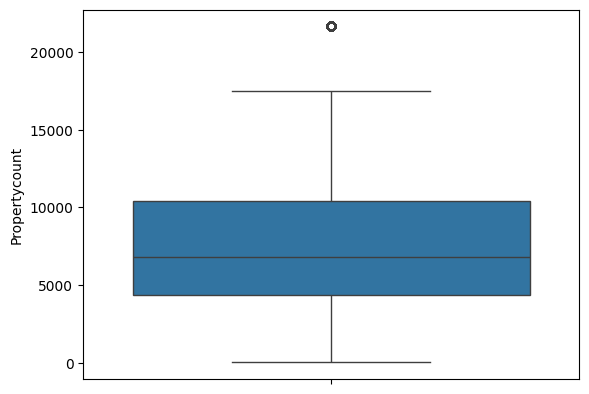

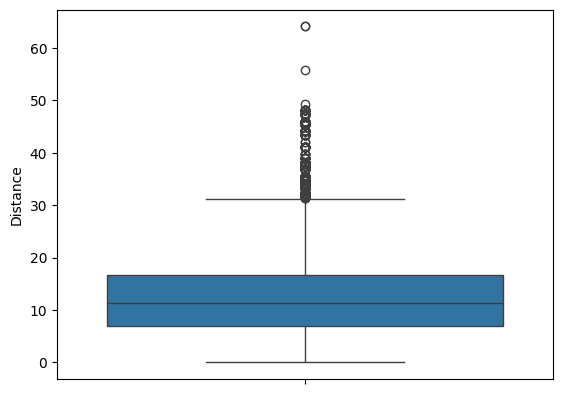

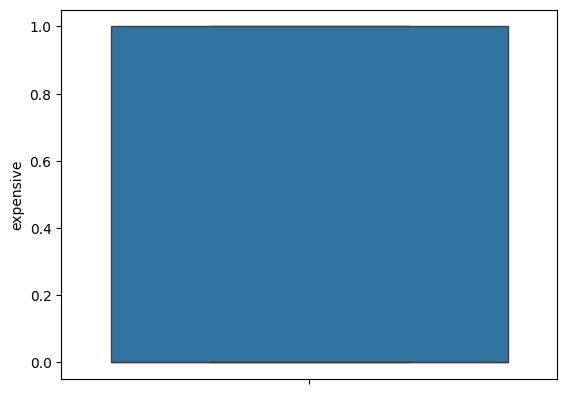

In [123]:
for i in numeri:
    sns.boxplot(house[i])
    plt.show()

In [125]:
for i in numeri:
    q1=house[i].quantile(0.25)
    q3=house[i].quantile(0.75)
    iqr=q3-q1
    lw=q1-1.5*iqr
    uw=q3+1.5*iqr
    house[i]=np.where(house[i]<lw,lw,np.where(house[i]>uw,uw,house[i]))

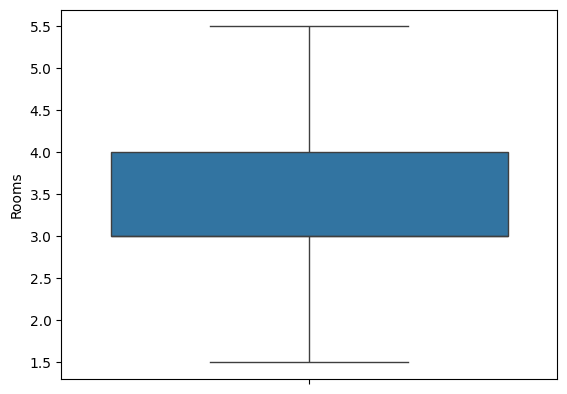

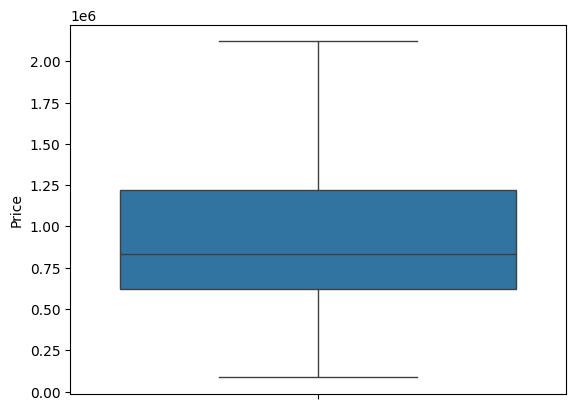

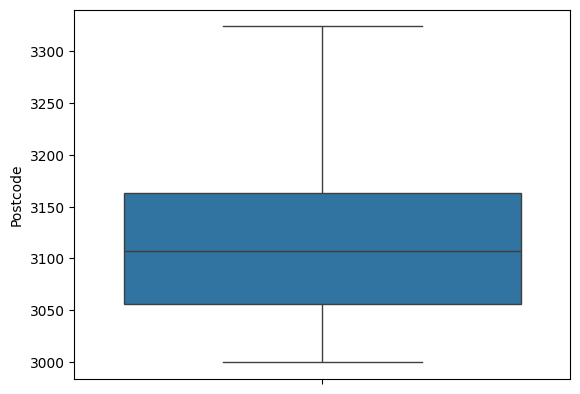

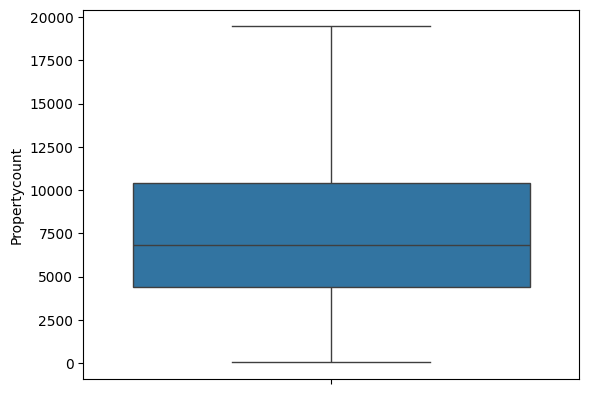

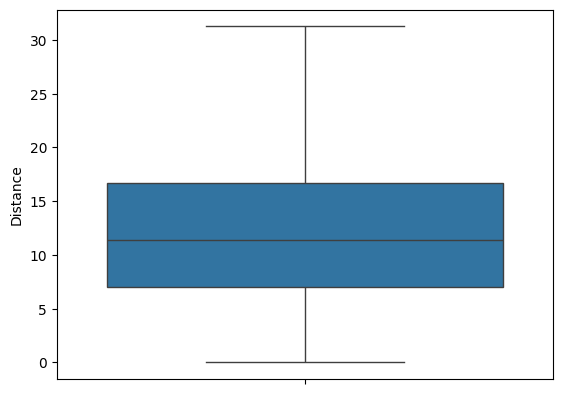

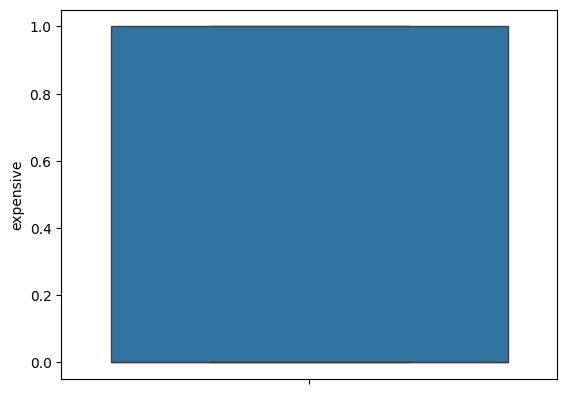

In [126]:
for i in numeri:
    sns.boxplot(house[i])
    plt.show()

In [11]:
house.head(2)

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,49 Lithgow St,3,h,1490000.0,S,Jellis,2017-01-04,3067,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,59A Turner St,3,h,1220000.0,S,Marshall,2017-01-04,3067,Northern Metropolitan,4019,3.0,Yarra City Council


In [12]:
copy=house.copy()

In [ ]:
# supervised models
## Linear regression


In [ ]:
# apply one hot for categorical and standscaler for numeric data


In [15]:
categ=[  'Type',
'Method',
'SellerG',
'Regionname',
'CouncilArea' ,  'Suburb'    ]

In [17]:
for i in categ:
   # if house[i].nunique():
       print(i, house[i].nunique())

Type 3
Method 9
SellerG 476
Regionname 8
CouncilArea 34
Suburb 380


In [18]:
enc=OneHotEncoder()

In [21]:
onehot=enc.fit_transform(house[['Type','Method','Regionname']])

In [33]:
numeric=house.select_dtypes(np.number).columns
numeric

Index(['Rooms', 'Price', 'Postcode', 'Propertycount', 'Distance'], dtype='object')

In [28]:
scaler=StandardScaler()

In [35]:
scal=scaler.fit_transform(house[numeric.drop('Price',)])

In [ ]:
ColumnTransformer(['categorical',enc,['Type','Method','Regionname']],['scaler',scaler,])

In [38]:
d=pd.read_csv('database.csv')
d.shape

(2795, 48)

In [40]:
d.isna().sum().sort_values(ascending=False)

All Fatalities                          2787
Operator Employee Fatalities            2787
Operator Contractor Fatalities          2787
Emergency Responder Fatalities          2787
Other Fatalities                        2787
Public Fatalities                       2787
Emergency Responder Injuries            2783
Operator Employee Injuries              2783
Other Injuries                          2783
Public Injuries                         2783
All Injuries                            2783
Operator Contractor Injuries            2783
Liquid Name                             2573
Intentional Release (Barrels)           1586
Restart Date/Time                       1454
Liquid Subtype                          1446
Shutdown Date/Time                      1405
Public Evacuations                       457
Accident City                            315
Pipeline Shutdown                        212
Pipeline/Facility Name                   121
Accident County                           75
Pipeline T

In [ ]:
line=Unintentional Release (Barrels),All Fatalities,All Injuries,Pipeline Type,Cause Category

In [ ]:
kmeans=Unintentional Release (Barrels),All Fatalities,All Injuries,All Costs

In [44]:
d['Unintentional Release (Barrels)'].fillna(d['Unintentional Release (Barrels)'].mean(),inplace=True)
d['All Fatalities'].fillna(d['All Fatalities'].mean(),inplace=True)
d['Pipeline Type'].fillna(d['Pipeline Type'].mode(),inplace=True)


In [46]:
d.drop(columns=['Public Fatalities','Operator Employee Fatalities','Operator Contractor Fatalities','Emergency Responder Fatalities',
               'Other Fatalities','Operator Contractor Injuries','Other Injuries','Public Injuries','All Injuries','Operator Employee Injuries',
               'Emergency Responder Injuries','Liquid Name'],axis=1,inplace=True)

In [48]:
d.drop(columns=['Intentional Release (Barrels)','Restart Date/Time','Liquid Subtype','Shutdown Date/Time'],axis=1,inplace=True)

In [50]:
d.dropna(inplace=True)

In [51]:
d.isna().sum().sort_values(ascending=False)

Report Number                           0
Supplemental Number                     0
Other Costs                             0
Environmental Remediation Costs         0
Emergency Response Costs                0
Public/Private Property Damage Costs    0
Lost Commodity Costs                    0
Property Damage Costs                   0
All Fatalities                          0
Public Evacuations                      0
Pipeline Shutdown                       0
Liquid Explosion                        0
Liquid Ignition                         0
Net Loss (Barrels)                      0
Liquid Recovery (Barrels)               0
Unintentional Release (Barrels)         0
Cause Subcategory                       0
Cause Category                          0
Accident Longitude                      0
Accident Latitude                       0
Accident State                          0
Accident County                         0
Accident City                           0
Liquid Type                       

In [56]:
d['high_cost']=(d['All Costs']>1000000).astype('int')
d['high_cost']

11      0
14      0
16      1
17      0
19      0
       ..
2787    0
2790    0
2792    0
2793    0
2794    0
Name: high_cost, Length: 1923, dtype: int32

In [58]:
d.select_dtypes(np.number).columns

Index(['Report Number', 'Supplemental Number', 'Accident Year', 'Operator ID',
       'Accident Latitude', 'Accident Longitude',
       'Unintentional Release (Barrels)', 'Liquid Recovery (Barrels)',
       'Net Loss (Barrels)', 'Public Evacuations', 'All Fatalities',
       'Property Damage Costs', 'Lost Commodity Costs',
       'Public/Private Property Damage Costs', 'Emergency Response Costs',
       'Environmental Remediation Costs', 'Other Costs', 'All Costs',
       'high_cost'],
      dtype='object')

In [59]:
d.select_dtypes('object').columns

Index(['Accident Date/Time', 'Operator Name', 'Pipeline/Facility Name',
       'Pipeline Location', 'Pipeline Type', 'Liquid Type', 'Accident City',
       'Accident County', 'Accident State', 'Cause Category',
       'Cause Subcategory', 'Liquid Ignition', 'Liquid Explosion',
       'Pipeline Shutdown'],
      dtype='object')

In [73]:
preprocess=ColumnTransformer([('scale',StandardScaler(),d.select_dtypes(np.number).columns.tolist()),('categor',OneHotEncoder(),d.select_dtypes('object').columns.tolist())
                             ])
preprocess

ColumnTransformer(transformers=[('scale', StandardScaler(),
                                 ['Report Number', 'Supplemental Number',
                                  'Accident Year', 'Operator ID',
                                  'Accident Latitude', 'Accident Longitude',
                                  'Unintentional Release (Barrels)',
                                  'Liquid Recovery (Barrels)',
                                  'Net Loss (Barrels)', 'Public Evacuations',
                                  'All Fatalities', 'Property Damage Costs',
                                  'Lost Commodity Costs',
                                  'Public/Private Property Damage Cos...
                                  'Emergency Response Costs',
                                  'Environmental Remediation Costs',
                                  'Other Costs', 'All Costs', 'high_cost']),
                                ('categor', OneHotEncoder(),
                                 ['Accident Date/Time', 'Operator Name',
                                  'Pipeline/Facility Name', 'Pipeline Location',
                                  'Pipeline Type', 'Liquid Type',
                                  'Accident City', 'Accident County',
                                  'Accident State', 'Cause Category',
                                  'Cause Subcategory', 'Liquid Ignition',
                                  'Liquid Explosion', 'Pipeline Shutdown'])])

In [75]:
x=d[['Unintentional Release (Barrels)','All Fatalities','Pipeline Type','Cause Category']]
y=d['Property Damage Costs']

In [76]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=32)

In [78]:
numer=x_train.select_dtypes(np.number).columns.tolist()
cat=x_train.select_dtypes('object').columns.tolist()


In [83]:
preproces=ColumnTransformer([('scale',StandardScaler(),numer),('categor',OneHotEncoder(),cat) ])

In [84]:
linear_pipe=Pipeline([('preprocess',preproces),('linearregression',LinearRegression())])

In [85]:
linear_pipe.fit(x_train,y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('scale', StandardScaler(),
                                                  ['Unintentional Release '
                                                   '(Barrels)',
                                                   'All Fatalities']),
                                                 ('categor', OneHotEncoder(),
                                                  ['Pipeline Type',
                                                   'Cause Category'])])),
                ('linearregression', LinearRegression())])

In [86]:
predi=linear_pipe.predict(x_test)

In [88]:
resid=y_test-predi
resid

2069   -1.156445e+04
181    -1.696598e+05
398    -1.338212e+04
1447   -1.475714e+05
741    -1.110919e+04
            ...     
2536    3.132024e+04
2229    3.023049e+04
1750   -1.561795e+05
1465   -1.712527e+04
1406    3.549913e+06
Name: Property Damage Costs, Length: 385, dtype: float64

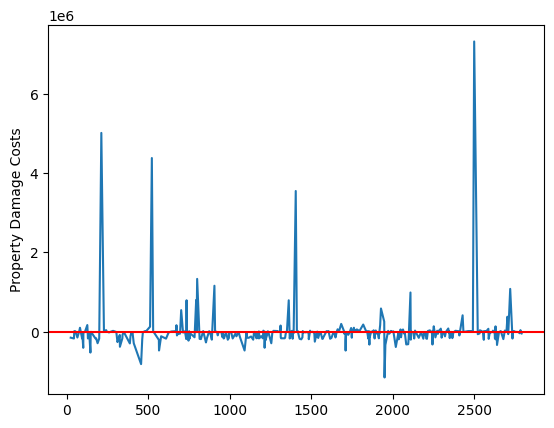

In [90]:
sns.lineplot(resid)
plt.axhline(color='r')

In [ ]:
d['Pipeline Shutdown']

In [91]:
x=d.drop('Pipeline Shutdown',axis=1)
y=d['Pipeline Shutdown']

In [92]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=32)

In [93]:
numer=x_train.select_dtypes(np.number).columns.tolist()
cat=x_train.select_dtypes('object').columns.tolist()

In [94]:
preproces=ColumnTransformer([('scale',StandardScaler(),numer),('categor',OneHotEncoder(),cat) ])

In [96]:
log_pipe=Pipeline([('preprocess',preproces),('logis',LogisticRegression())])

In [101]:
rand_pipe=Pipeline([('preprocess',preproces),('rand',RandomForestClassifier())])

In [102]:
rand_pipe.fit(x_train,y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('scale', StandardScaler(),
                                                  ['Report Number',
                                                   'Supplemental Number',
                                                   'Accident Year',
                                                   'Operator ID',
                                                   'Accident Latitude',
                                                   'Accident Longitude',
                                                   'Unintentional Release '
                                                   '(Barrels)',
                                                   'Liquid Recovery (Barrels)',
                                                   'Net Loss (Barrels)',
                                                   'Public Evacuations',
                                                   'All Fatalities',
                                                   'Property Damage Costs',
                                                   'Lost Commodity Costs',...
                                                   'Environmental Remediation '
                                                   'Costs',
                                                   'Other Costs', 'All Costs',
                                                   'high_cost']),
                                                 ('categor', OneHotEncoder(),
                                                  ['Accident Date/Time',
                                                   'Operator Name',
                                                   'Pipeline/Facility Name',
                                                   'Pipeline Location',
                                                   'Pipeline Type',
                                                   'Liquid Type',
                                                   'Accident City',
                                                   'Accident County',
                                                   'Accident State',
                                                   'Cause Category',
                                                   'Cause Subcategory',
                                                   'Liquid Ignition',
                                                   'Liquid Explosion'])])),
                ('rand', RandomForestClassifier())])

In [103]:
rand_pipe.get_feature_names_out

<bound method Pipeline.get_feature_names_out of Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('scale', StandardScaler(),
                                                  ['Report Number',
                                                   'Supplemental Number',
                                                   'Accident Year',
                                                   'Operator ID',
                                                   'Accident Latitude',
                                                   'Accident Longitude',
                                                   'Unintentional Release '
                                                   '(Barrels)',
                                                   'Liquid Recovery (Barrels)',
                                                   'Net Loss (Barrels)',
                                                   'Public Evacuations',
                                                   'All F

In [115]:
pipesteps=rand_pipe.named_steps
pipesteps

{'preprocess': ColumnTransformer(transformers=[('scale', StandardScaler(),
                                  ['Report Number', 'Supplemental Number',
                                   'Accident Year', 'Operator ID',
                                   'Accident Latitude', 'Accident Longitude',
                                   'Unintentional Release (Barrels)',
                                   'Liquid Recovery (Barrels)',
                                   'Net Loss (Barrels)', 'Public Evacuations',
                                   'All Fatalities', 'Property Damage Costs',
                                   'Lost Commodity Costs',
                                   'Public/Private Property Damage Cos...
                                   'Emergency Response Costs',
                                   'Environmental Remediation Costs',
                                   'Other Costs', 'All Costs', 'high_cost']),
                                 ('categor', OneHotEncoder(),
        

In [118]:
pipesteps['preprocess'].transformers_[0][2]

['Report Number',
 'Supplemental Number',
 'Accident Year',
 'Operator ID',
 'Accident Latitude',
 'Accident Longitude',
 'Unintentional Release (Barrels)',
 'Liquid Recovery (Barrels)',
 'Net Loss (Barrels)',
 'Public Evacuations',
 'All Fatalities',
 'Property Damage Costs',
 'Lost Commodity Costs',
 'Public/Private Property Damage Costs',
 'Emergency Response Costs',
 'Environmental Remediation Costs',
 'Other Costs',
 'All Costs',
 'high_cost']

In [119]:
pipesteps['preprocess'].transformers_[1][2]

['Accident Date/Time',
 'Operator Name',
 'Pipeline/Facility Name',
 'Pipeline Location',
 'Pipeline Type',
 'Liquid Type',
 'Accident City',
 'Accident County',
 'Accident State',
 'Cause Category',
 'Cause Subcategory',
 'Liquid Ignition',
 'Liquid Explosion']

In [121]:
pipesteps['rand'].feature_importances_

array([0.02654187, 0.02752027, 0.01340123, ..., 0.00181722, 0.00048069,
       0.00024763])

In [126]:
model=pipesteps['rand']
model.n_classes_

2

In [131]:
pipesteps['rand'].feature_importances_

array([0.02654187, 0.02752027, 0.01340123, ..., 0.00181722, 0.00048069,
       0.00024763])

In [132]:
x=d[['Unintentional Release (Barrels)','All Fatalities','All Costs']]

In [133]:
from sklearn.cluster import KMeans

In [134]:
inertia=[]
for i in range(1,11):
    kmean=KMeans(n_clusters=i,random_state=32)
    kmean.fit(x)
    inertia.append(kmean.inertia_)

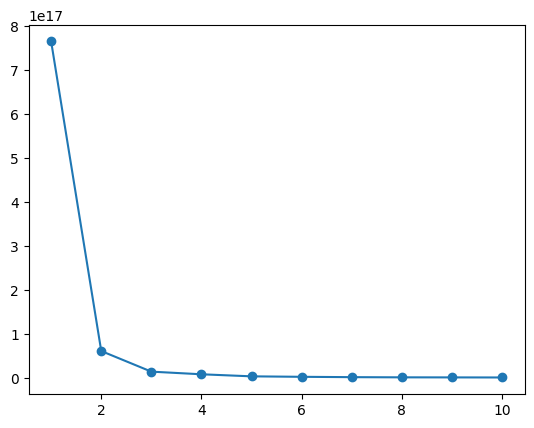

In [138]:
plt.plot(range(1,11),inertia,marker='o')

In [148]:
k=3
kmeans=KMeans(n_clusters=k)
clus=kmeans.fit_predict(scaled_data)
np.unique(clus)

array([0, 1, 2])

In [139]:
scaled=StandardScaler()
scaled_data=scaled.fit_transform(x)

In [143]:
scaled_data


array([[-0.16432885, -0.00475501, -0.03692039],
       [-0.15167626, -0.00475501, -0.05380556],
       [ 0.14636271, -0.00475501,  0.07134295],
       ...,
       [-0.1657347 , -0.00475501, -0.05407031],
       [-0.16629704, -0.00475501, -0.05274841],
       [-0.16362593, -0.00475501, -0.05252931]])

In [150]:
label=kmeans.labels_
silhouette_score(scaled_data,label)

0.9865126304677002

In [153]:
pca=PCA(n_components=3)
pca.fit(scaled_data)

PCA(n_components=3)

In [154]:
from sklearn.tree import DecisionTreeClassifier

In [159]:
x=d[['Unintentional Release (Barrels)','All Fatalities']]
y=d['Property Damage Costs']

In [160]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=32)

In [161]:
deci=DecisionTreeClassifier()
deci.fit(x_train,y_train)

DecisionTreeClassifier()

[Text(0.3875, 0.9166666666666666, 'Unintentional Release (Barrels) <= 2.88\ngini = 0.955\nsamples = 1538\nvalue = [292.0, 1.0, 1.0, 4.0, 3.0, 3.0, 7.0, 1.0, 1.0, 19.0\n1.0, 1.0, 1.0, 47.0, 1.0, 1.0, 5.0, 1.0, 20.0, 1.0\n1.0, 1.0, 16.0, 12.0, 4.0, 1.0, 1.0, 8.0, 1.0, 1.0\n1.0, 52.0, 1.0, 5.0, 3.0, 4.0, 1.0, 3.0, 1.0, 4.0\n1.0, 1.0, 1.0, 1.0, 1.0, 61.0, 1.0, 1.0, 1.0, 1.0\n3.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 20.0, 1.0\n2.0, 1.0, 2.0, 2.0, 1.0, 1.0, 1.0, 1.0, 31.0, 1.0\n1.0, 1.0, 2.0, 1.0, 1.0, 5.0, 1.0, 22.0, 1.0, 1.0\n1.0, 1.0, 2.0, 1.0, 1.0, 2.0, 1.0, 15.0, 1.0, 1.0\n1.0, 2.0, 1.0, 1.0, 1.0, 9.0, 1.0, 2.0, 1.0, 2.0\n1.0, 1.0, 10.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0\n1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 44.0, 1.0, 3.0\n1.0, 1.0, 1.0, 1.0, 2.0, 1.0, 1.0, 1.0, 12.0, 1.0\n1.0, 1.0, 1.0, 3.0, 1.0, 1.0, 1.0, 1.0, 1.0, 14.0\n1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 1.0, 1.0, 1.0\n7.0, 1.0, 1.0, 4.0, 1.0, 4.0, 2.0, 1.0, 1.0, 1.0\n1.0, 1.0, 1.0, 47.0, 4.0, 1.0, 1.0, 1.0, 1.0, 4.0\n1.0, 1.0, 1.0, 2.

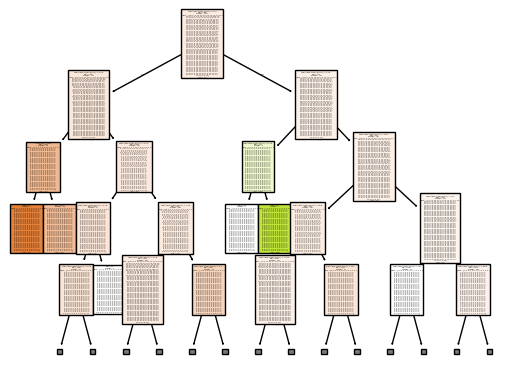

In [163]:
plot_tree(deci,max_depth=4,feature_names=x.columns,class_names=True,filled=True)